In [ ]:
#libraries
import numpy as np
import cv2
import matplotlib.pyplot as plt
%matplotlib inline
import pywt
from math import log10, sqrt,log
from PIL import Image

# 1. alpha and beta

In [ ]:
alpha = 0.999
beta = 1 - alpha

# 2. Load Images
Read CI and resize it to 256 ×256; read PI and resize it to 512 ×512.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
PI = cv2.imread("/content/drive/MyDrive/Colab Notebooks/cameraman.tif")
PI = PI[:,:,0]

In [ ]:
PI.shape

(512, 512)

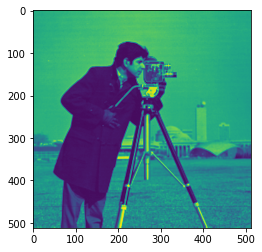

In [ ]:
plt.imshow(PI);

In [ ]:
CI = cv2.imread("/content/drive/MyDrive/Colab Notebooks/lena_gray_256.tif")
CI = CI[:,:,0]

In [ ]:
CI.shape

(256, 256)

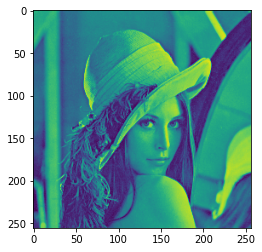

In [ ]:
plt.imshow(CI);

# 3. Normalization
Normalize Cover Image (NCI) = CI/255 and Normalize Pay- load Image (NPI) = PI/255.

In [ ]:
Normalized_CI = CI/255
Normalized_PI = PI/255

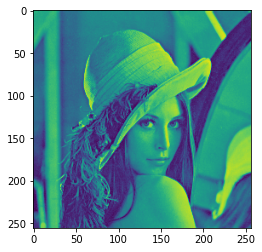

In [ ]:
plt.imshow(Normalized_CI);

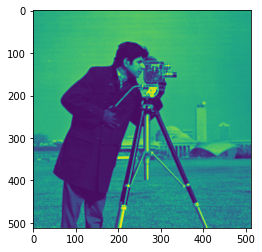

In [ ]:
plt.imshow(Normalized_PI);

# 4. Preprocessing
Preprocessing Cover Image (PCI) = (NCI) ∗ 𝛼and Preprocess- ing Payload Image (PPI) = (NPI ∗ 𝛽).

In [ ]:
processing_CI = Normalized_CI * alpha
processing_PI = Normalized_PI * beta

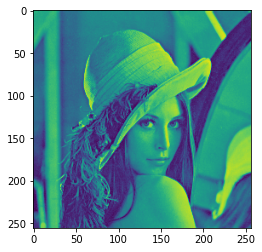

In [ ]:
plt.imshow(processing_CI);

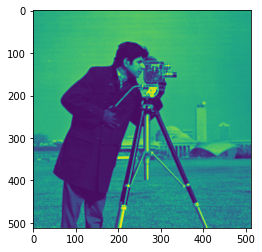

In [ ]:
plt.imshow(processing_PI);

# 5. DWT

## 5.1 Cover Image (CI)

In [ ]:
coeffs_CI = pywt.dwt2(processing_CI, 'db1')
LL_CI, (LH_CI, HL_CI, HH_CI) = coeffs_CI

## 5.2 Payload Image (PI)

In [ ]:
coeffs_PI = pywt.dwt2(processing_PI, 'db1')
LL_PI, (LH_PI, HL_PI, HH_PI) = coeffs_PI

# 6. Encryption

In [ ]:
def dec(bitSequence):
    decimal = 0
    for bit in bitSequence:
        decimal = decimal * 2 + int(bit)
    return decimal

In [ ]:
def genHenonMap(dimension, key):
    x = key[0]
    y = key[1]
    sequenceSize = dimension * dimension * 8 #Total Number of bitSequence produced
    bitSequence = []    #Each bitSequence contains 8 bits
    byteArray = []      #Each byteArray contains m( i.e 512 in this case) bitSequence
    TImageMatrix = []   #Each TImageMatrix contains m*n byteArray( i.e 512 byteArray in this case)
    for i in range(sequenceSize):
        xN = y + 1 - 1.4 * x**2
        yN = 0.3 * x

        x = xN
        y = yN

        if xN <= 0.4:
            bit = 0
        else:
            bit = 1

        try:
            bitSequence.append(bit)
        except:
            bitSequence = [bit]

        if i % 8 == 7:
            decimal = dec(bitSequence)
            try:
                byteArray.append(decimal)
            except:
                byteArray = [decimal]
            bitSequence = []

        byteArraySize = dimension*8
        if i % byteArraySize == byteArraySize-1:
            try:
                TImageMatrix.append(byteArray)
            except:
                TImageMatrix = [byteArray]
            byteArray = []
    return TImageMatrix

In [ ]:
def getImageMatrix(imageName):
    #im = Image.open(imageName)
    #pix = im.load()
    color = 1
    if type(pix[0,0]) == int:
      color = 0
    image_size = imageName.size
    image_matrix = []
    for width in range(int(image_size[0])):
        row = []
        for height in range(int(image_size[1])):
                row.append((pix[width,height]))
        image_matrix.append(row)
    return image_matrix,image_size[0],color

In [ ]:
def HenonEncryption(imageName,key):
    imageMatrix, dimension, color = getImageMatrix(imageName)
    transformationMatrix = genHenonMap(dimension, key)
    resultantMatrix = []
    for i in range(dimension):
        row = []
        for j in range(dimension):
            try:
                if color:
                    row.append(tuple([transformationMatrix[i][j] ^ x for x in imageMatrix[i][j]]))
                else:
                    row.append(transformationMatrix[i][j] ^ imageMatrix[i][j])
            except:
                if color:
                    row = [tuple([transformationMatrix[i][j] ^ x for x in imageMatrix[i][j]])]
                else :
                    row = [transformationMatrix[i][j] ^ x for x in imageMatrix[i][j]]
        try:
            resultantMatrix.append(row)
        except:
            resultantMatrix = [row]
    if color:
      im = Image.new("RGB", (dimension, dimension))
    else:
      im = Image.new("L", (dimension, dimension)) # L is for Black and white pixels

    pix = im.load()
    for x in range(dimension):
        for y in range(dimension):
            pix[x, y] = resultantMatrix[x][y]
    return im

In [ ]:
def HenonDecryption(imageNameEnc, key):
    imageMatrix, dimension, color = getImageMatrix(imageNameEnc)
    transformationMatrix = genHenonMap(dimension, key)
    #pil_im = Image.open(imageNameEnc, 'r')
    #plt.imshow(np.asarray(pil_im))
    henonDecryptedImage = []
    for i in range(dimension):
        row = []
        for j in range(dimension):
            try:
                if color:
                    row.append(tuple([transformationMatrix[i][j] ^ x for x in imageMatrix[i][j]]))
                else:
                    row.append(transformationMatrix[i][j] ^ imageMatrix[i][j])
            except:
                if color:
                    row = [tuple([transformationMatrix[i][j] ^ x for x in imageMatrix[i][j]])]
                else :
                    row = [transformationMatrix[i][j] ^ x for x in imageMatrix[i][j]]
        try:
            henonDecryptedImage.append(row)
        except:
            henonDecryptedImage = [row]
    if color:
        im = Image.new("RGB", (dimension, dimension))
    else:
        im = Image.new("L", (dimension, dimension)) # L is for Black and white pixels

    pix = im.load()
    for x in range(dimension):
        for y in range(dimension):
            pix[x, y] = henonDecryptedImage[x][y]
    return im

In [ ]:
key = (0.1,0.1)

In [ ]:
LL_PI_encry = HenonEncryption(LL_PI,key)
LH_PI_encry = HenonEncryption(LH_PI,key)
HL_PI_encry = HenonEncryption(HL_PI,key)
HH_PI_encry = HenonEncryption(HH_PI,key)

NameError: ignored

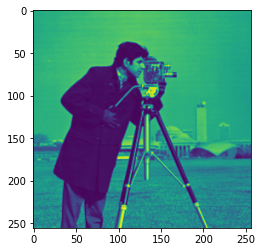

In [ ]:
plt.imshow(LL_PI);

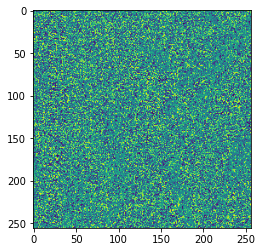

In [ ]:
plt.imshow(LL_PI_encry);

In [ ]:
print(LL_PI_encry)

<PIL.Image.Image image mode=L size=256x256 at 0x7FEC34E0CBE0>


In [ ]:
print(LL_CI)

[[1.26931765 1.27323529 1.28107059 ... 0.9324     1.1988     1.27715294]
 [1.26735882 1.26148235 1.25756471 ... 0.96765882 1.08714706 0.94415294]
 [1.22426471 1.22818235 1.24581176 ... 0.89322353 0.52888235 0.38197059]
 ...
 [0.41527059 0.4329     0.48187059 ... 0.4662     0.4329     0.44661176]
 [0.40351765 0.40743529 0.45640588 ... 0.46815882 0.49166471 0.65228824]
 [0.38197059 0.40351765 0.42898235 ... 0.51321176 0.69538235 0.78940588]]


In [ ]:

LL_PI_encry = np.array(LL_PI_encry)
LL_PI_encry = LL_PI_encry.astype(np.float64)

LH_PI_encry = np.array(LH_PI_encry)
LH_PI_encry = LH_PI_encry.astype(np.float64)

HL_PI_encry = np.array(HL_PI_encry)
HL_PI_encry = HL_PI_encry.astype(np.float64)

HH_PI_encry = np.array(HH_PI_encry)
HH_PI_encry = HH_PI_encry.astype(np.float64)


In [ ]:
print(LL_PI_encry.shape)
print(LL_CI.shape)
print(LL_PI_encry.dtype)
print(LL_CI.dtype)

(256, 256)
(128, 128)
float64
float64


# 7. Fusion
Embedding the payload in CI to generate a Stego Image (SI), i.e., LL, LH, HL, HH bands of encrypted PI are embedded in respective bands of the CI using fusion

In [ ]:
print(LL_CI.shape)
print(LL_PI_encry.shape)

(128, 128)
(256, 256)


In [ ]:
fused_LL = cv2.add(LL_CI, cv2.resize(LL_PI_encry, (128,128)))
fused_LH = cv2.add(LH_CI, cv2.resize(LH_PI_encry, (128,128)))
fused_HL = cv2.add(HL_CI, cv2.resize(HL_PI_encry, (128,128)))
fused_HH = cv2.add(HH_CI, cv2.resize(HH_PI_encry, (128,128)))

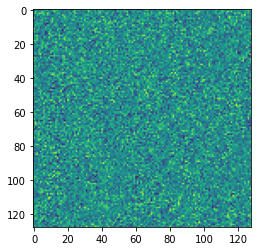

In [ ]:
plt.imshow(fused_LL);

# 8. IDWT

In [ ]:
coeffs = fused_LL, (fused_LH, fused_HL, fused_HH)

In [ ]:
inversed = pywt.idwt2(coeffs, 'db1')

In [ ]:
stego = inversed * 255

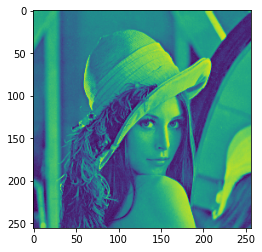

In [ ]:
plt.imshow(stego);

# 9.Result

In [ ]:
mse = np.sum((stego - CI) ** 2)
mse /= stego.shape[0] * stego.shape[1]
mse

0.006491549957273621

In [ ]:
psnr = 20 * log10(255 / sqrt(mse))
psnr

70.00731957207184

---

# Secret Image Extraction

##1. Read Stego Image

In [ ]:
stego_img = stego /255

## 2. DWT

In [ ]:
coeffs_SI = pywt.dwt2(stego_img, 'db1')
LL_SI, (LH_SI, HL_SI, HH_SI) = coeffs_SI

## 3. Subtraction
Subtraction of SI coefficients from CI coefficients

In [ ]:
LL_subtract = cv2.subtract(LL_SI, LL_CI)
LH_subtract = cv2.subtract(LH_SI, LH_CI)
HL_subtract = cv2.subtract(HL_SI, HL_CI)
HH_subtract = cv2.subtract(HH_SI, HH_CI)

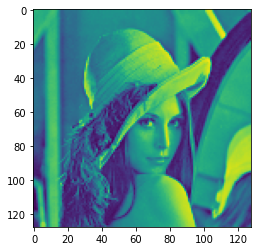

In [ ]:
plt.imshow(LL_SI);

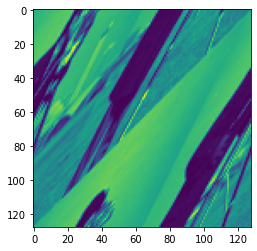

In [ ]:
plt.imshow(LL_subtract);

In [ ]:
subtract_coeffs = LL_subtract, (LH_subtract, HL_subtract, HH_subtract)
subtract_idwt = pywt.idwt2(subtract_coeffs, 'db1')

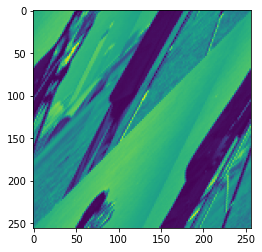

In [ ]:
plt.imshow(subtract_idwt/beta);

## 5.Decryption


In [ ]:
def ArnoldCatDecryption(imageName, key):
    # img = cv2.imread(imageName)
    rows, cols = imageName.shape
    dimension = rows
    decrypt_it = dimension
    if (dimension%2==0) and 5**int(round(log(dimension/2,5))) == int(dimension/2):
        decrypt_it = 3*dimension
    elif 5**int(round(log(dimension,5))) == int(dimension):
        decrypt_it = 2*dimension
    elif (dimension%6==0) and  5**int(round(log(dimension/6,5))) == int(dimension/6):
        decrypt_it = 2*dimension
    else:
        decrypt_it = int(12*dimension/7)
    for i in range(key,decrypt_it):
        img = ArnoldCatTransform(imageName, i)
    # cv2.imwrite(imageName.split('_')[0] + "_ArnoldcatDec.png",img)
    return img

In [ ]:
# decrypted_img = ArnoldCatDecryption(subtract_idwt, 20)
decrypted_LL = ArnoldCatDecryption(LL_subtract, 20)
decrypted_LH = ArnoldCatDecryption(LH_subtract, 20)
decrypted_HL = ArnoldCatDecryption(HL_subtract, 20)
decrypted_HH = ArnoldCatDecryption(HH_subtract, 20)

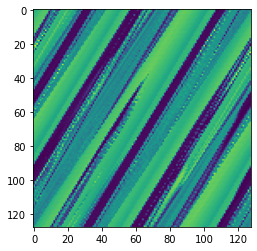

In [ ]:
plt.imshow(decrypted_LL);

## 4.IDWT

In [ ]:
subtract_coeffs = decrypted_LL, (decrypted_LH, decrypted_HL, decrypted_HH)
subtract_idwt = pywt.idwt2(subtract_coeffs, 'db1')

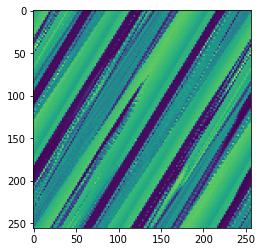

In [ ]:
plt.imshow(subtract_idwt/beta);



---



---





---



---



# Trying Arnold Cat Encryption on a separate image

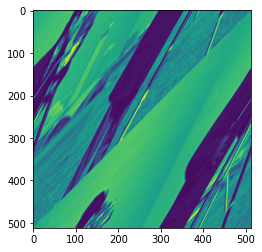

In [ ]:
img = ArnoldCatEncryption(PI, 20)
plt.imshow(img);

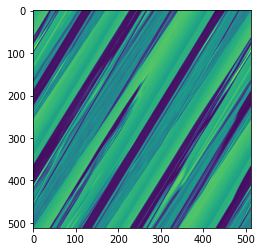

In [ ]:
dec_img = ArnoldCatDecryption(img, 20)
plt.imshow(dec_img);



---



---



In [ ]:
image = "/content/drive/MyDrive/Colab Notebooks/cameraman.tif"
key = (0.1,0.1)

In [ ]:
from PIL import Image

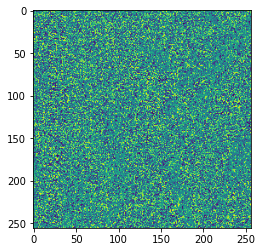

In [ ]:
im = HenonEncryption(image, key)
plt.imshow(np.asarray(im))

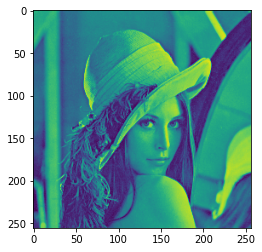

In [ ]:
im = HenonEncryption(image, key)
Decimg = HenonDecryption(im,key)
plt.imshow(np.asarray(Decimg))

HenonEncryption(image + ext, key)
im = Image.open(image + "_HenonEnc.png", 'r')
imshow(np.asarray(im))
     

In [ ]:
HenonDecryption(image + "_HenonEnc.png", key)
im = Image.open(image + "_HenonDec.png", 'r')
plt.imshow(np.asarray(im))

In [ ]:
image = "/content/drive/MyDrive/Colab Notebooks/lena_gray_256.tif"
key = (0.1, 0.1)

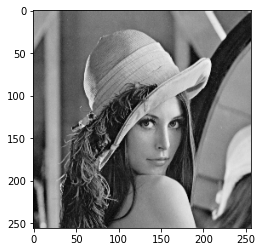

In [ ]:
pil_im = Image.open(image, 'r')
plt.imshow(np.asarray(pil_im), cmap='gray')


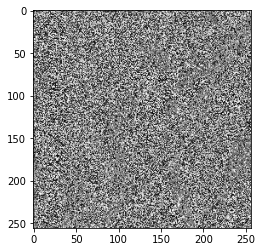

In [ ]:
im = HenonEncryption(image, key)
plt.imshow(np.asarray(im), cmap='gray')

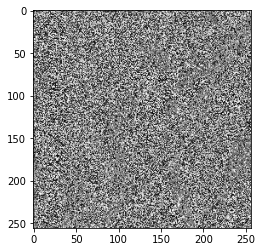

In [ ]:
im = HenonDecryption(image, key)
plt.imshow(np.asarray(im), cmap='gray')

# Trying New Encryption Technique

In [ ]:
from PIL import Image

In [ ]:
def getImageMatrix_gray(imageName):
    im = Image.open(imageName).convert('LA')
    pix = im.load()
    image_size = im.size
    image_matrix = []
    for width in range(int(image_size[0])):
        row = []
        for height in range(int(image_size[1])):
                row.append((pix[width,height]))
        image_matrix.append(row)
    return image_matrix, image_size[0], image_size[1]

In [ ]:
def LogisticEncryption(imageName, key):
    N = 256
    key_list = [ord(x) for x in key]
    G = [key_list[0:4] ,key_list[4:8], key_list[8:12]]
    g = []
    R = 1
    for i in range(1,4):
        s = 0
        for j in range(1,5):
            s += G[i-1][j-1] * (10**(-j))
        g.append(s)
        R = (R*s) % 1

    L = (R + key_list[12]/256) % 1
    S_x = round(((g[0]+g[1]+g[2])*(10**4) + L *(10**4)) % 256)
    V1 = sum(key_list)
    V2 = key_list[0]
    for i in range(1,13):
        V2 = V2 ^ key_list[i]
    V = V2/V1

    L_y = (V+key_list[12]/256) % 1
    S_y = round((V+V2+L_y*10**4) % 256)
    C1_0 = S_x
    C2_0 = S_y
    C = round((L*L_y*10**4) % 256)
    C_r = round((L*L_y*10**4) % 256)
    C_g = round((L*L_y*10**4) % 256)
    C_b = round((L*L_y*10**4) % 256)
    x = 4*(S_x)*(1-S_x)
    y = 4*(S_y)*(1-S_y)

    imageMatrix,dimensionX, dimensionY = getImageMatrix_gray(imageName)
    LogisticEncryptionIm = []
    for i in range(dimensionX):
        row = []
        for j in range(dimensionY):
            while x <0.8 and x > 0.2 :
                x = 4*x*(1-x)
            while y <0.8 and y > 0.2 :
                y = 4*y*(1-y)
            x_round = round((x*(10**4))%256)
            y_round = round((y*(10**4))%256)
            C1 = x_round ^ ((key_list[0]+x_round) % N) ^ ((C1_0 + key_list[1])%N)
            C2 = x_round ^ ((key_list[2]+y_round) % N) ^ ((C2_0 + key_list[3])%N)
            if color:
              C_r =((key_list[4]+C1) % N) ^ ((key_list[5]+C2) % N) ^ ((key_list[6]+imageMatrix[i][j][0]) % N) ^ ((C_r + key_list[7]) % N)
              C_g =((key_list[4]+C1) % N) ^ ((key_list[5]+C2) % N) ^ ((key_list[6]+imageMatrix[i][j][1]) % N) ^ ((C_g + key_list[7]) % N)
              C_b =((key_list[4]+C1) % N) ^ ((key_list[5]+C2) % N) ^ ((key_list[6]+imageMatrix[i][j][2]) % N) ^ ((C_b + key_list[7]) % N)
              row.append((C_r,C_g,C_b))
              C = C_r

            else:
             C = ((key_list[4]+C1) % N) ^ ((key_list[5]+C2) % N) ^ ((key_list[6]+imageMatrix[i][j]) % N) ^ ((C + key_list[7]) % N)
            row.append(C)

            x = (x + C/256 + key_list[8]/256 + key_list[9]/256) % 1
            y = (x + C/256 + key_list[8]/256 + key_list[9]/256) % 1
            for ki in range(12):
                key_list[ki] = (key_list[ki] + key_list[12]) % 256
                key_list[12] = key_list[12] ^ key_list[ki]
        LogisticEncryptionIm.append(row)

    im = Image.new("L", (dimensionX, dimensionY))
    if color:
        im = Image.new("RGB", (dimensionX, dimensionY))
    else:
        im = Image.new("L", (dimensionX, dimensionY)) # L is for Black and white pixels

    pix = im.load()
    for x in range(dimensionX):
        for y in range(dimensionY):
            pix[x, y] = LogisticEncryptionIm[x][y]
    im.save(imageName.split('.')[0] + "_LogisticEnc.png", "PNG")


IndentationError: ignored

In [ ]:
LogisticEncryption("/content/drive/MyDrive/Colab Notebooks/System Science (Msc) 2023/lena_gray_256.tif","abcdefghijklm")

In [ ]:
im_encry = Image.open("lena_gray_256_LogisticEnc.png", 'r')

In [ ]:
plt.imshow(im_encry);

In [ ]:
def LogisticDecryption(imageName, key):
    N = 256
    key_list = [ord(x) for x in key]

    G = [key_list[0:4] ,key_list[4:8], key_list[8:12]]
    g = []
    R = 1
    for i in range(1,4):
        s = 0
        for j in range(1,5):
            s += G[i-1][j-1] * (10**(-j))
        g.append(s)
        R = (R*s) % 1

    L_x = (R + key_list[12]/256) % 1
    S_x = round(((g[0]+g[1]+g[2])*(10**4) + L_x *(10**4)) % 256)
    V1 = sum(key_list)
    V2 = key_list[0]
    for i in range(1,13):
        V2 = V2 ^ key_list[i]
    V = V2/V1

    L_y = (V+key_list[12]/256) % 1
    S_y = round((V+V2+L_y*10**4) % 256)
    C1_0 = S_x
    C2_0 = S_y

    C = round((L_x*L_y*10**4) % 256)
    I_prev = C
    I_prev_r = C
    I_prev_g = C
    I_prev_b = C
    I = C
    I_r = C
    I_g = C
    I_b = C
    x_prev = 4*(S_x)*(1-S_x)
    y_prev = 4*(L_x)*(1-S_y)
    x = x_prev
    y = y_prev
    imageMatrix,dimensionX, dimensionY, color = getImageMatrix_gray(imageName)

    henonDecryptedImage = []
    for i in range(dimensionX):
        row = []
        for j in range(dimensionY):
            while x <0.8 and x > 0.2 :
                x = 4*x*(1-x)
            while y <0.8 and y > 0.2 :
                y = 4*y*(1-y)
            x_round = round((x*(10**4))%256)
            y_round = round((y*(10**4))%256)
            C1 = x_round ^ ((key_list[0]+x_round) % N) ^ ((C1_0 + key_list[1])%N)
            C2 = x_round ^ ((key_list[2]+y_round) % N) ^ ((C2_0 + key_list[3])%N)
            if color:
                I_r = ((((key_list[4]+C1) % N) ^ ((key_list[5]+C2) % N) ^ ((I_prev_r + key_list[7]) % N) ^ imageMatrix[i][j][0]) + N-key_list[6])%N
                I_g = ((((key_list[4]+C1) % N) ^ ((key_list[5]+C2) % N) ^ ((I_prev_g + key_list[7]) % N) ^ imageMatrix[i][j][1]) + N-key_list[6])%N
                I_b = ((((key_list[4]+C1) % N) ^ ((key_list[5]+C2) % N) ^ ((I_prev_b + key_list[7]) % N) ^ imageMatrix[i][j][2]) + N-key_list[6])%N
                I_prev_r = imageMatrix[i][j][0]
                I_prev_g = imageMatrix[i][j][1]
                I_prev_b = imageMatrix[i][j][2]
                row.append((I_r,I_g,I_b))
                x = (x +  imageMatrix[i][j][0]/256 + key_list[8]/256 + key_list[9]/256) % 1
                y = (x +  imageMatrix[i][j][0]/256 + key_list[8]/256 + key_list[9]/256) % 1
            else:
                I = ((((key_list[4]+C1) % N) ^ ((key_list[5]+C2) % N) ^ ((I_prev+key_list[7]) % N) ^ imageMatrix[i][j]) + N-key_list[6])%N
                I_prev = imageMatrix[i][j]
                row.append(I)
                x = (x +  imageMatrix[i][j]/256 + key_list[8]/256 + key_list[9]/256) % 1
                y = (x +  imageMatrix[i][j]/256 + key_list[8]/256 + key_list[9]/256) % 1
            for ki in range(12):
                key_list[ki] = (key_list[ki] + key_list[12]) % 256
                key_list[12] = key_list[12] ^ key_list[ki]
        henonDecryptedImage.append(row)
    if color:
        im = Image.new("RGB", (dimensionX, dimensionY))
    else:
        im = Image.new("L", (dimensionX, dimensionY)) # L is for Black and white pixels
    pix = im.load()
    for x in range(dimensionX):
        for y in range(dimensionY):
            pix[x, y] = henonDecryptedImage[x][y]
    im.save(imageName.split('_')[0] + "_LogisticDec.png", "PNG")

In [ ]:
LogisticDecryption("lena_gray_256_LogisticEnc.png","abcdefghijklm")

In [ ]:
im_dec = Image.open("lena_LogisticDec.png", 'r')

In [ ]:
plt.imshow(im_dec);